# Pokemon ML Test Run 3

In [1]:
import numpy as np 
import pandas as pd 
import matplotlib.pyplot as plt 
import seaborn as sns

# Models 
from sklearn.model_selection import train_test_split 
from sklearn.linear_model import LogisticRegression 

from sklearn.tree import DecisionTreeClassifier 
from sklearn.ensemble import RandomForestClassifier 

# Cross Validation 
from sklearn.model_selection import GridSearchCV 
from sklearn.model_selection import KFold 

# OneHotEncoder 
from sklearn.preprocessing import OneHotEncoder
enc = OneHotEncoder(handle_unknown="ignore")
from sklearn.feature_extraction import FeatureHasher

# Metrics
from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import precision_score
from sklearn.metrics import recall_score
from sklearn.metrics import mean_absolute_error
from sklearn.metrics import roc_curve, auc
from sklearn.metrics import f1_score
from sklearn.metrics import classification_report

# Time
import time 

### Reading in the data

In [2]:
pokemon = pd.read_csv("../pokemon.csv")
combats = pd.read_csv("../combats.csv")
tests = pd.read_csv("../tests.csv")

In [3]:
pokemon.head()

,#,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
0,1,Bulbasaur,Grass,Poison,45,49,49,65,65,45,1,False
1,2,Ivysaur,Grass,Poison,60,62,63,80,80,60,1,False
2,3,Venusaur,Grass,Poison,80,82,83,100,100,80,1,False
3,4,Mega Venusaur,Grass,Poison,80,100,123,122,120,80,1,False
4,5,Charmander,Fire,NaN,39,52,43,60,50,65,1,False


In [4]:
combats.head()

,First_pokemon,Second_pokemon,Winner
0,266,298,298
1,702,701,701
2,191,668,668
3,237,683,683
4,151,231,151


In [5]:
tests.head()

,First_pokemon,Second_pokemon
0,129,117
1,660,211
2,706,115
3,195,618
4,27,656


### EDA

In [6]:
pokemon.info()

<class 'pandas.DataFrame'>
RangeIndex: 800 entries, 0 to 799
Data columns (total 12 columns):
 #   Column      Non-Null Count  Dtype
---  ------      --------------  -----
 0   #           800 non-null    int64
 1   Name        799 non-null    str  
 2   Type 1      800 non-null    str  
 3   Type 2      414 non-null    str  
 4   HP          800 non-null    int64
 5   Attack      800 non-null    int64
 6   Defense     800 non-null    int64
 7   Sp. Atk     800 non-null    int64
 8   Sp. Def     800 non-null    int64
 9   Speed       800 non-null    int64
 10  Generation  800 non-null    int64
 11  Legendary   800 non-null    bool 
dtypes: bool(1), int64(8), str(3)
memory usage: 82.8 KB


In [7]:
pokemon.shape

(800, 12)

In [8]:
combats.info()

<class 'pandas.DataFrame'>
RangeIndex: 50000 entries, 0 to 49999
Data columns (total 3 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   First_pokemon   50000 non-null  int64
 1   Second_pokemon  50000 non-null  int64
 2   Winner          50000 non-null  int64
dtypes: int64(3)
memory usage: 1.1 MB


In [9]:
combats.shape

(50000, 3)

In [10]:
tests.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 2 columns):
 #   Column          Non-Null Count  Dtype
---  ------          --------------  -----
 0   First_pokemon   10000 non-null  int64
 1   Second_pokemon  10000 non-null  int64
dtypes: int64(2)
memory usage: 156.4 KB


In [11]:
tests.shape

(10000, 2)

In [12]:
print(f"There are {len(pokemon)} Pokemon in our dataset.")

There are 800 Pokemon in our dataset.


In [13]:
print(f"There are {len(combats)} Pokemon battles in our dataset.")

There are 50000 Pokemon battles in our dataset.


In [14]:
pokemon[pokemon['Name'] == 'Raichu']

,#,Name,Type 1,Type 2,HP,Attack,Defense,Sp. Atk,Sp. Def,Speed,Generation,Legendary
31,32,Raichu,Electric,NaN,60,90,55,90,80,110,1,False


In [15]:
pokemon['Type 1'].value_counts()

Type 1
Water       112
Normal       98
Grass        70
Bug          69
Psychic      57
Fire         52
Electric     44
Rock         44
Ground       32
Ghost        32
Dragon       32
Dark         31
Poison       28
Fighting     27
Steel        27
Ice          24
Fairy        17
Flying        4
Name: count, dtype: int64

In [16]:
pokemon['Type 2'].value_counts()

Type 2
Flying      97
Ground      35
Poison      34
Psychic     33
Fighting    26
Grass       25
Fairy       23
Steel       22
Dark        20
Dragon      18
Ice         14
Rock        14
Water       14
Ghost       14
Fire        12
Electric     6
Normal       4
Bug          3
Name: count, dtype: int64

In [17]:
type1_counts = pokemon['Type 1'].value_counts()
type2_counts = pokemon['Type 2'].value_counts()

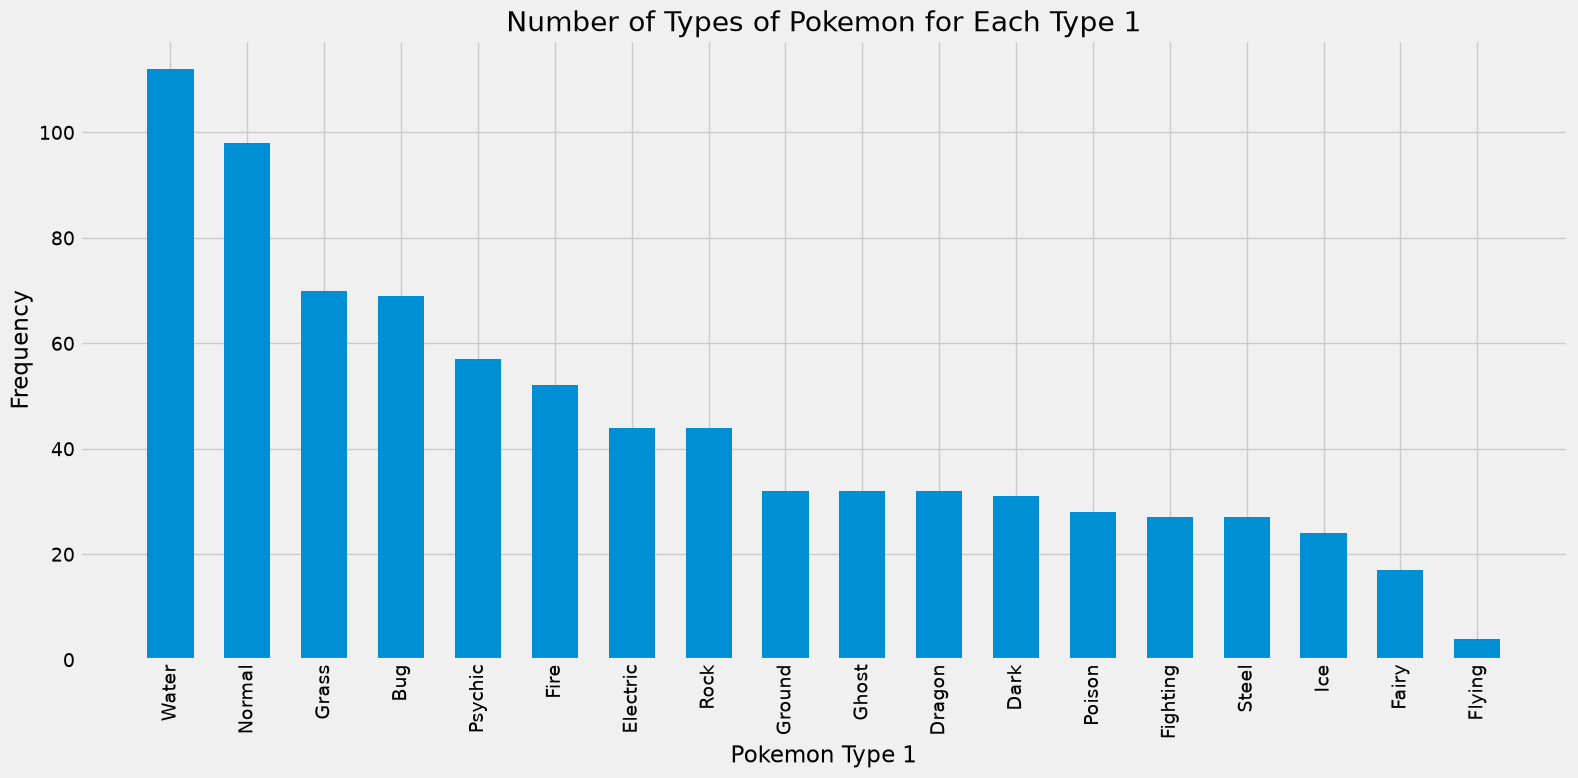

In [19]:
plt.style.use('fivethirtyeight')

plt.figure(figsize=(16, 8))
width=0.6

plt.bar(type1_counts.index, type1_counts.values, width=width)

plt.title("Number of Types of Pokemon for Each Type 1")
plt.xlabel("Pokemon Type 1")
plt.ylabel("Frequency")

plt.xticks(rotation=90)

plt.tight_layout()
plt.show()

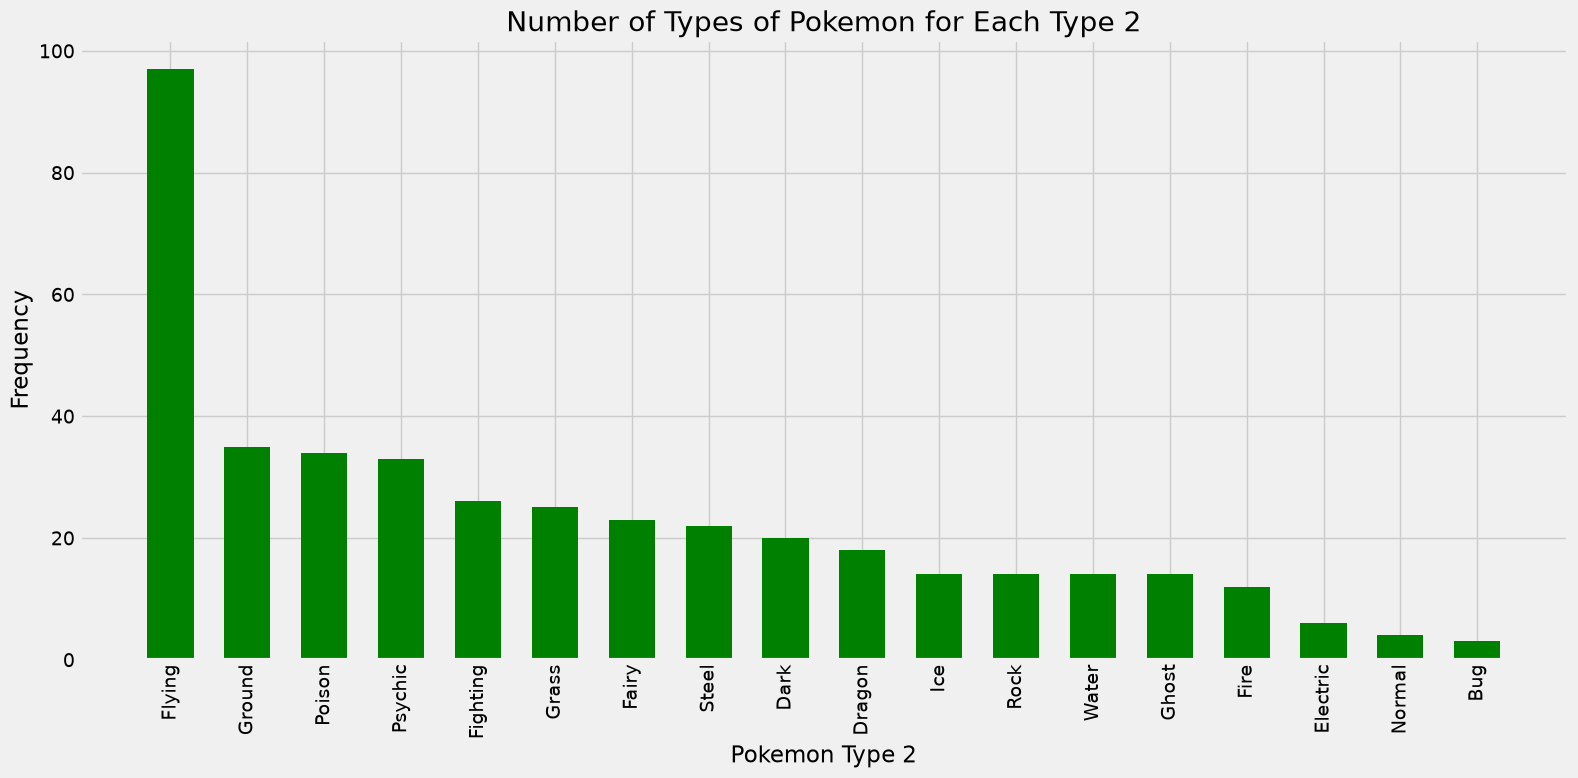

In [21]:
plt.style.use('fivethirtyeight')

plt.figure(figsize=(16, 8))
width=0.6

plt.bar(type2_counts.index, type2_counts.values, width=width, color='green')

plt.title("Number of Types of Pokemon for Each Type 2")
plt.xlabel("Pokemon Type 2")
plt.ylabel("Frequency")

plt.xticks(rotation=90)
plt.tight_layout()
plt.show()